# Term Project Milestone 1: Data Selection and EDA

Video game development is a high-cost, high-risk industry. Studios can spend years and millions of dollars building a new game, only to find that it underperforms in the market.  In an industry where the global market exceeds $180 billion annually, the ability to forecast sales before launch could provide a major competitive advantage and better investment.  Publishers and developers want to make informed decisions about which projects to greenlight, which platforms to target, and how to manage budgets efficiently.

The business problem addressed in this project is predicting a game’s global sales performance before release, based on its known characteristics. This potential predictive model could estimate sales potential using factors such as platform, genre, publisher, release year, and ESRB rating.  For example, certain genres may perform better on specific platforms or appeal to particular age demographics, while timing and platform trends could significantly influence overall demand.

The dataset selected for this project is Video Game Sales with Ratings data from Kaggle.  Reference URL: https://www.kaggle.com/datasets/rush4ratio/video-game-sales-with-ratings.  This dataset contains over 16,000 rows and 16 columns for game details such as Platform, Genre, Sales, and Review Scores.  

This analysis aims to uncover patterns between these attributes and actual sales figures.  By understanding which factors most strongly correlate with success, game publishers can better plan future releases and marketing strategies.  The target variable for the model will be Global_Sales.  Beyond predictive accuracy, the model’s insights could help reduce financial risk and improve strategic planning.  For example, smaller studios could use forecasts to decide whether to focus on niche genres with loyal audiences, while major publishers could use the model to prioritize high-potential titles for major investment.  Ultimately, data-driven forecasting offers a practical way to align creative ambition with commercial reality in one of the world’s most competitive entertainment industries.

## Graphical Analysis

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
#read in the data from a local csv
game_sales = pd.read_csv("Video_Games_Sales_as_at_22_Dec_2016.csv")

print(game_sales.info())
game_sales.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16719 entries, 0 to 16718
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16717 non-null  object 
 1   Platform         16719 non-null  object 
 2   Year_of_Release  16450 non-null  float64
 3   Genre            16717 non-null  object 
 4   Publisher        16665 non-null  object 
 5   NA_Sales         16719 non-null  float64
 6   EU_Sales         16719 non-null  float64
 7   JP_Sales         16719 non-null  float64
 8   Other_Sales      16719 non-null  float64
 9   Global_Sales     16719 non-null  float64
 10  Critic_Score     8137 non-null   float64
 11  Critic_Count     8137 non-null   float64
 12  User_Score       10015 non-null  object 
 13  User_Count       7590 non-null   float64
 14  Developer        10096 non-null  object 
 15  Rating           9950 non-null   object 
dtypes: float64(9), object(7)
memory usage: 2.0+ MB
None


,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006.0,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
#transformation to remove rows with NAN in Year of Release
game_sales = game_sales.dropna(subset = ["Year_of_Release"])

#transformation to remove .0 from Year_of_Release
game_sales["Year_of_Release"] = game_sales["Year_of_Release"].astype(int)

#transformation to convert User Score to numeric
game_sales["User_Score"] = pd.to_numeric(game_sales["User_Score"], errors = "coerce")

game_sales.head()

,Name,Platform,Year_of_Release,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Critic_Score,Critic_Count,User_Score,User_Count,Developer,Rating
0,Wii Sports,Wii,2006,Sports,Nintendo,41.36,28.96,3.77,8.45,82.53,76.0,51.0,8.0,322.0,Nintendo,E
1,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,NaN,NaN,NaN,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.68,12.76,3.79,3.29,35.52,82.0,73.0,8.3,709.0,Nintendo,E
3,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.61,10.93,3.28,2.95,32.77,80.0,73.0,8.0,192.0,Nintendo,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,NaN,NaN,NaN,NaN,NaN,NaN


### Graph 1: Distribution of Critic Scores

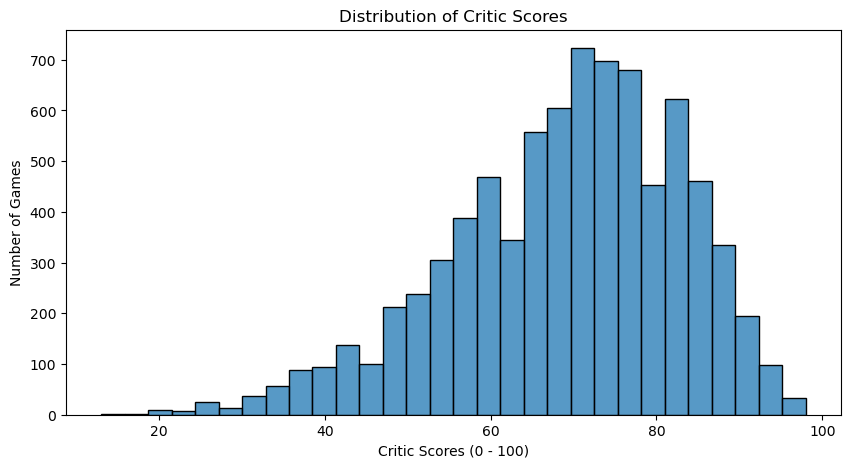

In [7]:
#plot histogram of Critic Score
plt.figure(figsize = (10, 5))
sns.histplot(game_sales["Critic_Score"], bins = 30)

plt.title("Distribution of Critic Scores")
plt.xlabel("Critic Scores (0 - 100)")
plt.ylabel("Number of Games")
plt.show()

In Graph 1, we can see that the majority of Critic Scores are in the higher half of the score range.  The peak of their scores are in the 70th percentile.

### Graph 2: Distribution of User Scores

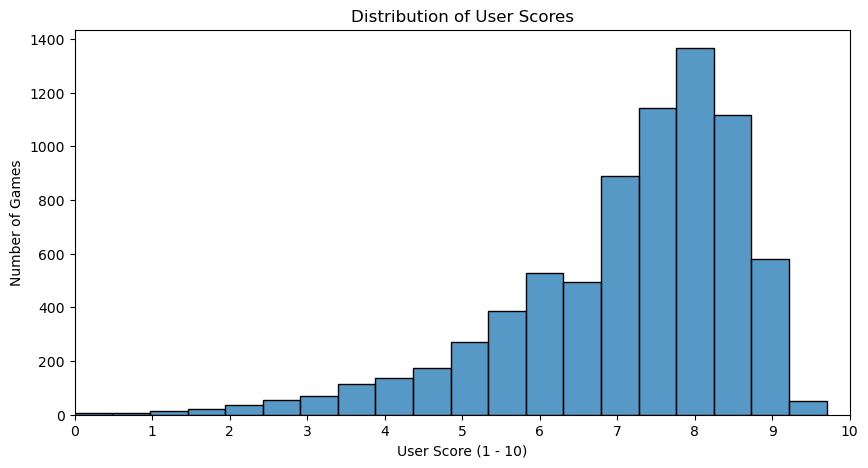

In [8]:
#use only valid scores between 0 and 10
filtered_scores = game_sales[(game_sales["User_Score"] >= 0) & (game_sales["User_Score"] <= 10)]

#plot histogram of User Score
plt.figure(figsize = (10, 5))
sns.histplot(data = filtered_scores, x = "User_Score", bins = 20)

plt.title("Distribution of User Scores")
plt.xlabel("User Score (1 - 10)")
plt.ylabel("Number of Games")

#set x-ticks and limit to 1-10 score range
plt.xticks(np.arange(0, 11, 1))
plt.xlim(0, 10)

plt.show()

In Graph 2, we get a view of the User Scores.  Similar to Graph 1, the majority of the User Scores are in the higher half of the score range.  The peak of User Scores is in the 80th percentile.  At first glance of Graph 1 and 2, Users seem to score games higher than Critics.

### Graph 3: Global Sales vs Critic Score

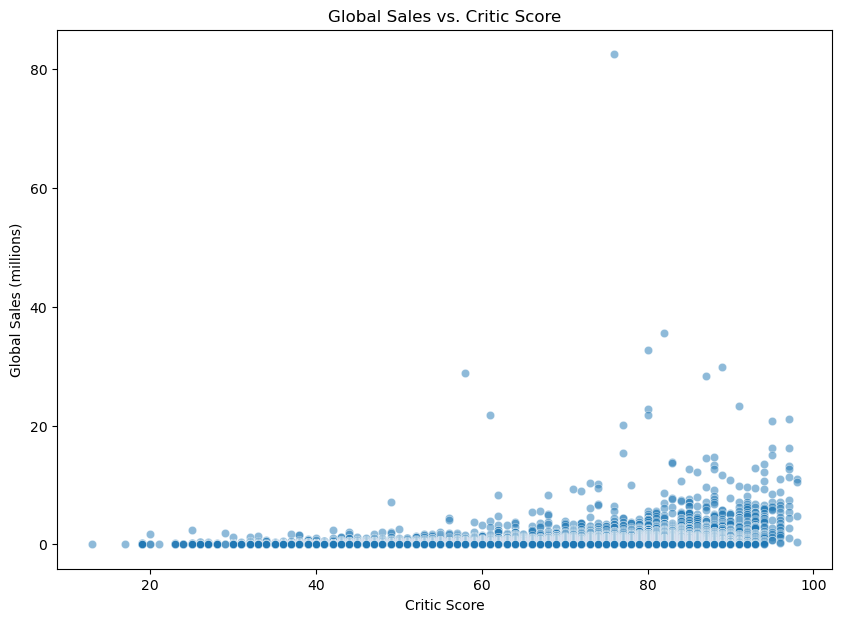

In [9]:
#plot scatterplot of Global Sales vs Critic Score
plt.figure(figsize = (10, 7))
sns.scatterplot(data = game_sales, x = "Critic_Score", y = "Global_Sales", alpha = 0.5)

plt.title("Global Sales vs. Critic Score")
plt.xlabel("Critic Score")
plt.ylabel("Global Sales (millions)")
plt.show()

Graph 3 shows us how Critic Scores line up agains Global Sales.  We can see a higher distribution in the higher half of Critic Score.  This leads us to believe that better critic scores will see better sales.

### Graph 4: Global Sales by Year of Release

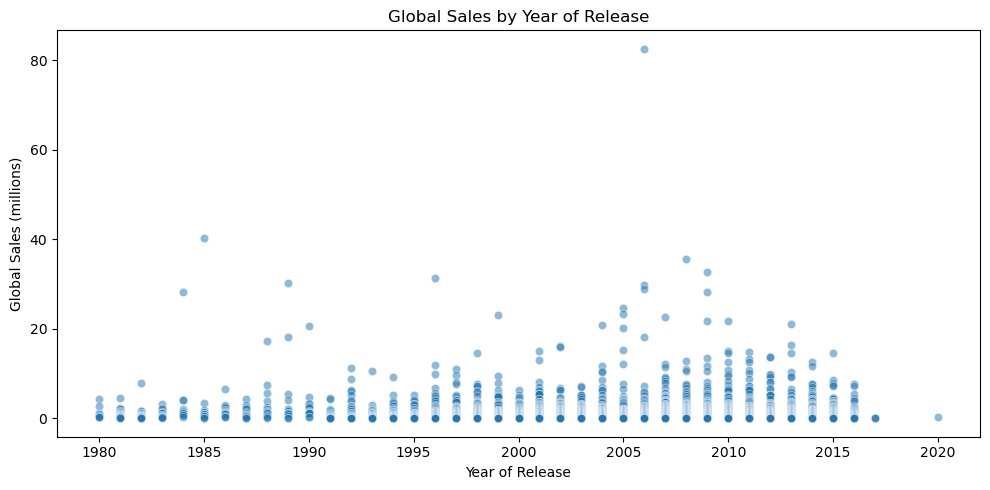

In [10]:
#plot scatterplot of Global Sales by Year of Release
plt.figure(figsize = (10, 5))
sns.scatterplot(data = game_sales, x = "Year_of_Release", y = "Global_Sales", alpha = 0.5)

plt.title("Global Sales by Year of Release")
plt.xlabel("Year of Release")
plt.ylabel("Global Sales (millions)")
plt.tight_layout()
plt.show()

Graph 4 shows how well games have sold globally between the years 1980 - 2016.  The 2020 outlier requires investigation.  You can see the trend where video game sales have continued to grow year by year.

### Graph 5: Global Sales by Publisher

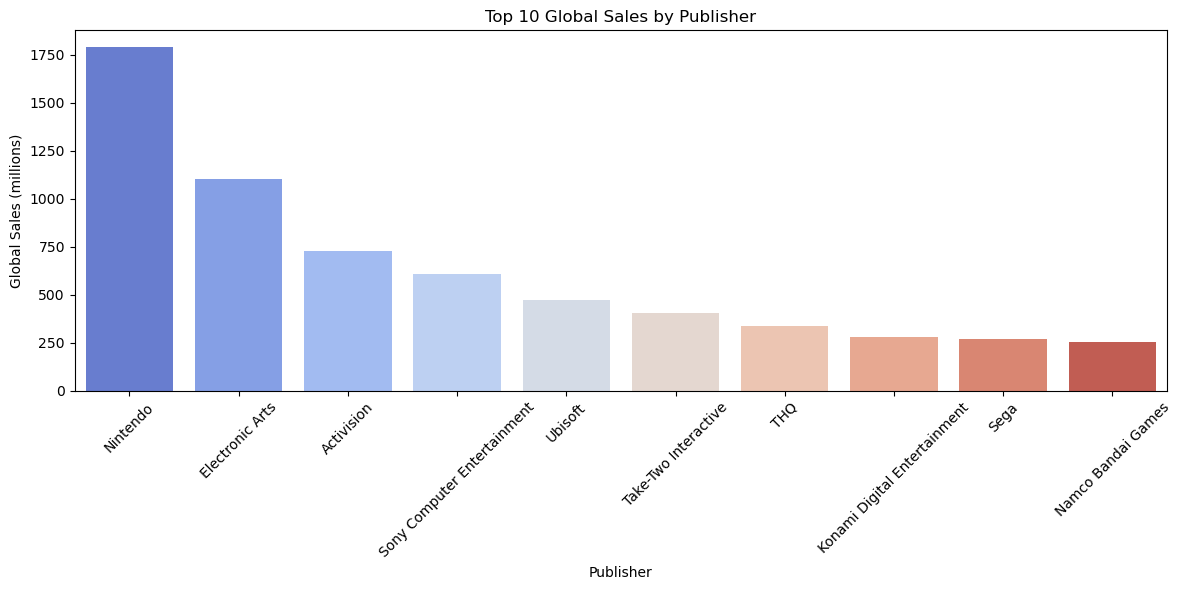

In [11]:
#aggregate sum of Global Sales per Publisher and display the Top 10
publisher_sales = (game_sales.groupby("Publisher")["Global_Sales"].sum().sort_values(ascending = False).head(10).reset_index())

#plot bar chart for Global Sales by Publisher
plt.figure(figsize = (12, 6))
sns.barplot(data = publisher_sales, x = "Publisher", y = "Global_Sales", hue = "Publisher", palette = "coolwarm", legend = False)

plt.title("Top 10 Global Sales by Publisher")
plt.xlabel("Publisher")
plt.ylabel("Global Sales (millions)")
plt.xticks(rotation = 45)  #rotate x ticks for readability 
plt.tight_layout()
plt.show()

Graph 5 shows us who the Top 10 Publishers are in Sales, since 1980.  Nintendo has been around much longer than most other publishers, so they have a comfortable lead over the other publishers.

### Graph 6: Global Sales by Genre

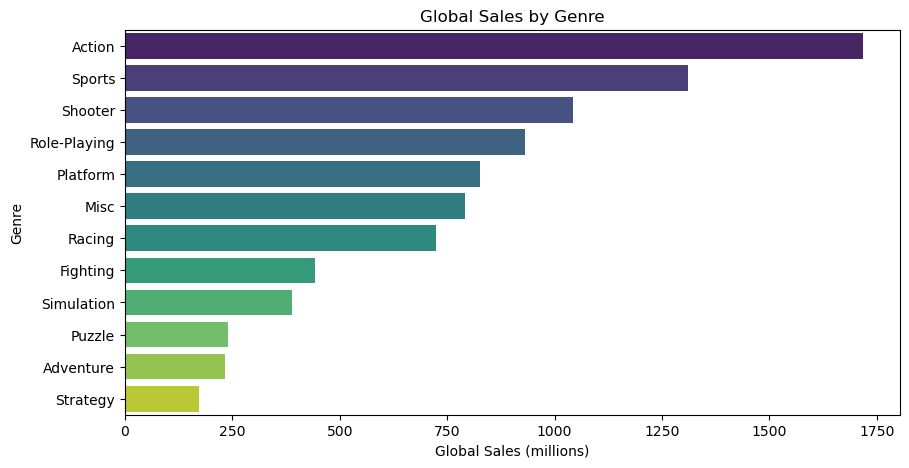

In [12]:
#aggregate sum of Global Sales per Genre
genre_sales = game_sales.groupby("Genre")["Global_Sales"].sum().sort_values(ascending = False).reset_index()

#plot bar chart for Global Sales by Genre
plt.figure(figsize = (10, 5))
sns.barplot(data = genre_sales, x = "Global_Sales", y = "Genre", hue = "Genre", palette = "viridis", legend = False)

plt.title("Global Sales by Genre")
plt.xlabel("Global Sales (millions)")
plt.ylabel("Genre")
plt.show()

Graph 6 shows us Global Sales by Genre.  Action, Sports, and Shooters are the top three in sales.  Game developers looking for successful, new titles should consider entering one of those three genres.

### Graph 7: Global Sales by Platform

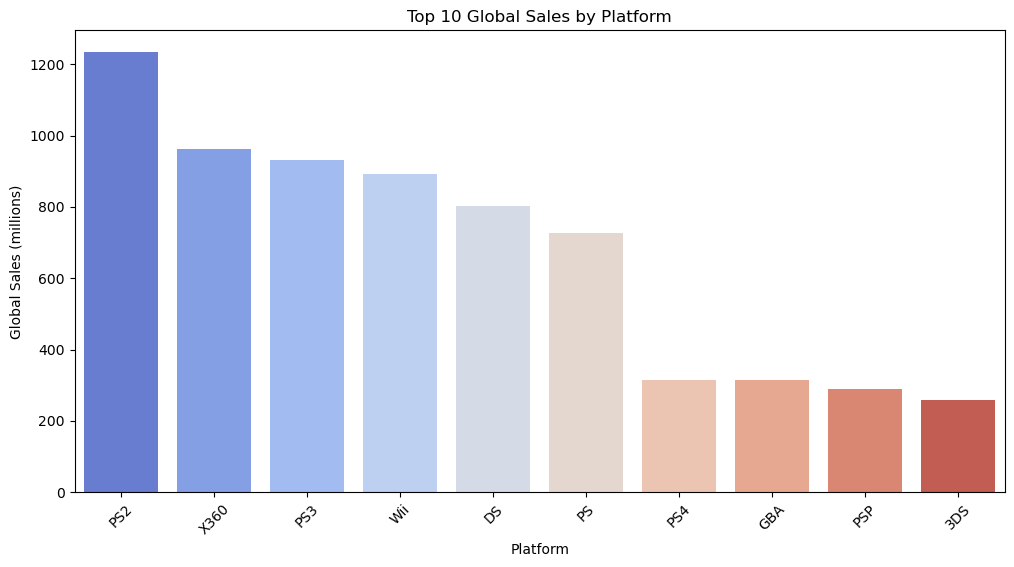

In [13]:
#aggregate sum of Global Sales per Platform and display the Top 10
platform_sales = (game_sales.groupby("Platform")["Global_Sales"].sum().sort_values(ascending = False).head(10).reset_index())

#plot barplot for Global Sales by Platform
plt.figure(figsize = (12, 6))
sns.barplot(data = platform_sales, x = "Platform", y = "Global_Sales", hue = "Platform", palette = "coolwarm", legend = False)        

plt.title("Top 10 Global Sales by Platform")
plt.xlabel("Platform")
plt.ylabel("Global Sales (millions)")
plt.xticks(rotation = 45)  #rotate x ticks for readability 
plt.show()

Graph 7 shows us how Game Platforms have sold over time.  The PS2, Xbox 360, and PS3 are the top three platforms.  It's interesting to get a view of the different systems by the industry giants: Nintendo (Wii, DS, GBA, 3DS), Playstation (PS2, PS3, PS, PS4, PSP), and Microsoft (Xbox360).

## Conclusion

In conclusion, we have gotten some good, initial insights into our video game sales dataset.  We have an early understanding of Critic Scores versus User Scores.  We have also gotten a glimpse at the Top Global Sales based on Critic Score, Year of Release, Publisher, Genre, and Platform.  These first insights will help in the next steps of building a model to predict sales from these features and measure its performance.  New features could also be considered where some can be combined together.

In [14]:
game_sales.to_csv("Video Game Sales - transformed.csv", index=False)